# Exponential Smoothing
Simple ES, Holts-Two-Parameter ES, Holt-Winters-Three Parameter ES

# Imports and Data Generation

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
#Generate sample data for basic forecasting example
#Monthly data for 5 years, data roughly constant, with small random fluctuations
np.random.seed(0)
date_rng = pd.date_range(start='1/1/2015', end='12/31/2019', freq='M')
data = pd.DataFrame(date_rng, columns=['date'])
data['Sales_Actuals'] = 100000 + 1000*(np.random.normal(0, 5, len(data)))
#round to integer
data['Sales_Actuals'] = data['Sales_Actuals'].round().astype(int)
data = data.set_index('date')
data.head()

/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_38354/794067782.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  date_rng = pd.date_range(start='1/1/2015', end='12/31/2019', freq='M')


,Sales_Actuals
date,
2015-01-31,108820
2015-02-28,102001
2015-03-31,104894
2015-04-30,111204
2015-05-31,109338


# Simple Exponential Smooting (SES)

In [3]:
#calculate simple exponential smoothing forecast with alpha=0.1 vs. 0,5
alpha = input("Enter alpha value for Simple Exponential Smoothing (between 0 and 1, e.g., 0.1 or 0.5): ")
alpha = float(alpha)
data['Simple_Exponential_Smoothing_Forecast'] = data['Sales_Actuals'].ewm(alpha=alpha, adjust=False).mean().shift(1)
#show first 10 rows but only sales actuals and simple exponential smoothing forecast
data.head(10)


,Sales_Actuals,Simple_Exponential_Smoothing_Forecast
date,,
2015-01-31,108820,NaN
2015-02-28,102001,108820.000000
2015-03-31,104894,108138.100000
2015-04-30,111204,107813.690000
2015-05-31,109338,108152.721000
2015-06-30,95114,108271.248900
2015-07-31,104750,106955.524010
2015-08-31,99243,106734.971609
2015-09-30,99484,105985.774448


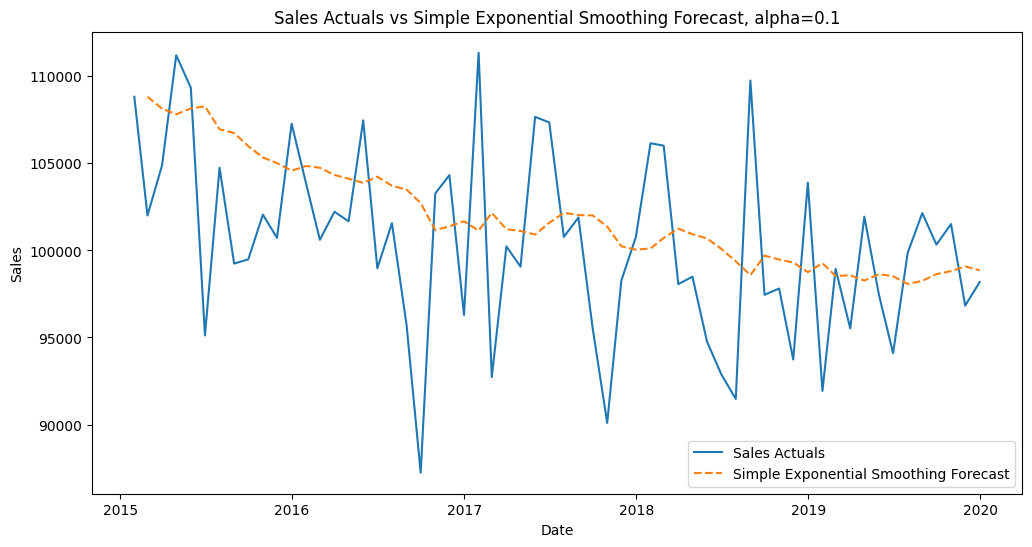

In [4]:
#plot simple exponential smoothing forecast vs sales actuals
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Actuals'], label='Sales Actuals')
plt.plot(data.index, data['Simple_Exponential_Smoothing_Forecast'], label='Simple Exponential Smoothing Forecast', linestyle='--')
plt.title('Sales Actuals vs Simple Exponential Smoothing Forecast, alpha={}'.format(alpha))
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Holts-Two-Parameter ES

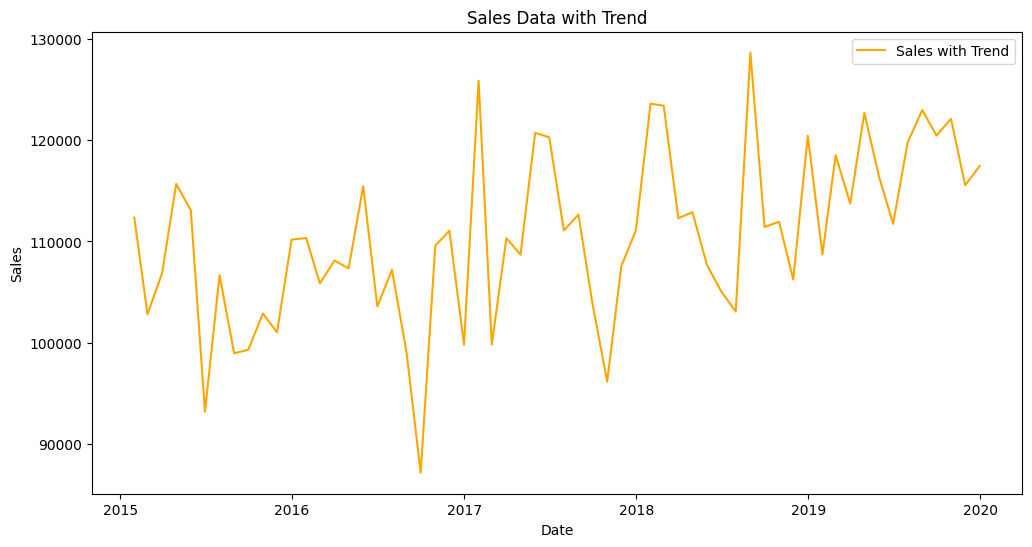

In [5]:
#add new time series data with trend for further forecasting methods
np.random.seed(0)
data['Sales_Trend'] = 5000 * (data.index.year - data.index.year.min()) + data['Sales_Actuals'] + np.random.normal(0, 2000, len(data))
#plot the new time series data with trend
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Trend'], label='Sales with Trend', color='orange')
plt.title('Sales Data with Trend')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

In [6]:
#Apply holt's linear trend method to forecast the new time series data with trend
from statsmodels.tsa.holtwinters import ExponentialSmoothing
holt_model = ExponentialSmoothing(data['Sales_Trend'], trend='add', seasonal=None)
holt_fit = holt_model.fit()
data['Holt_Linear_Trend_Forecast'] = holt_fit.fittedvalues.shift(1)
#show first 10 rows of sales actuals with trend and holt's linear trend forecast
data[['Sales_Trend', 'Holt_Linear_Trend_Forecast']].head(10)

/Users/hendrikmeth/Python/PYTHON_TIME_SERIES_FORECASTING/.venv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


,Sales_Trend,Holt_Linear_Trend_Forecast
date,,
2015-01-31,112348.104692,NaN
2015-02-28,102801.314417,111665.139788
2015-03-31,106851.475968,111908.704103
2015-04-30,115685.786398,110937.129651
2015-05-31,113073.115980,110588.832532
2015-06-30,93159.444240,111380.243104
2015-07-31,106650.176835,111749.153066
2015-08-31,98940.285583,109600.671946
2015-09-30,99277.562296,109393.266066


In [ ]:
#Print calculated level and trend of holt's linear trend model
final_level = holt_fit.level[-1]
final_trend = holt_fit.trend[-1]

print(f"Calculated level: {final_level:.3f}")
print(f"Calculated trend: {final_trend:.3f}")

#Print alpha and beta values of holt's linear trend model
print(f"Alpha (level smoothing parameter): {holt_fit.params['smoothing_level']:.3f}")
print(f"Beta (trend smoothing parameter): {holt_fit.params['smoothing_trend']:.3f}")

Calculated level: 118093.137
Calculated trend: 158.798
Alpha (level smoothing parameter): 0.124
Beta (trend smoothing parameter): 0.000


/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_38354/662052764.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_level = holt_fit.level[-1]
/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_38354/662052764.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_trend = holt_fit.trend[-1]


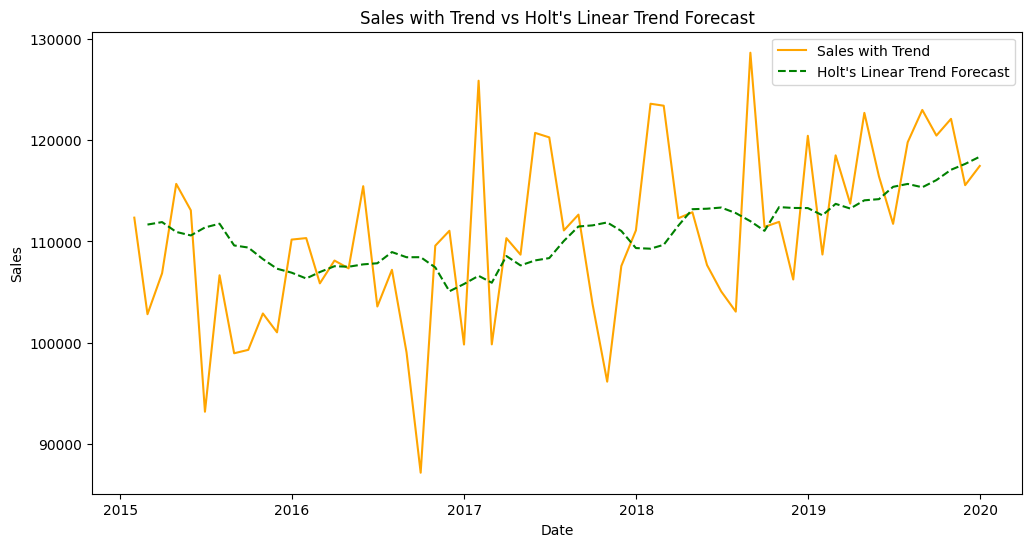

In [8]:
#plot sales_trend and holt's linear trend forecast
#show trend line as additional line on top of sales with trend
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Trend'], label='Sales with Trend', color='orange')
plt.plot(data.index, data['Holt_Linear_Trend_Forecast'], label="Holt's Linear Trend Forecast", linestyle='--', color='green')
plt.title("Sales with Trend vs Holt's Linear Trend Forecast")
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Holt-Winters-Three-Parameter Additive ES

In [9]:
#Generate sample data for seasonal+trend time series forecasting
np.random.seed(0)
data['Sales_Seasonal_Trend'] = (5000 * (data.index.year - data.index.year.min()) +
                                  1000 * np.sin(2 * np.pi * data.index.month / 12) +
                                  np.random.normal(0, 2000, len(data)))

In [10]:
#Calculate holt-winters seasonal method to forecast the new time series data with seasonal+trend
#Trend and seasonal are additive, seasonal period is 12 (monthly data)
holt_winters_model = ExponentialSmoothing(data['Sales_Seasonal_Trend'], trend='add', seasonal='add', seasonal_periods=12)
holt_winters_fit = holt_winters_model.fit()
data['Holt_Winters_Seasonal_Trend_Forecast'] = holt_winters_fit.fittedvalues.shift(1)

/Users/hendrikmeth/Python/PYTHON_TIME_SERIES_FORECASTING/.venv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [11]:
final_level = holt_winters_fit.level[-1]
final_trend = holt_winters_fit.trend[-1]
seasonality = holt_winters_model.seasonal_periods

print(f"Calculated level: {final_level:.3f}")
print(f"Calculated trend: {final_trend:.3f}")
print(f"Seasonality: {seasonality} months")


Calculated level: 21310.513
Calculated trend: 370.286
Seasonality: 12 months


/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_38354/648781999.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_level = holt_winters_fit.level[-1]
/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_38354/648781999.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_trend = holt_winters_fit.trend[-1]


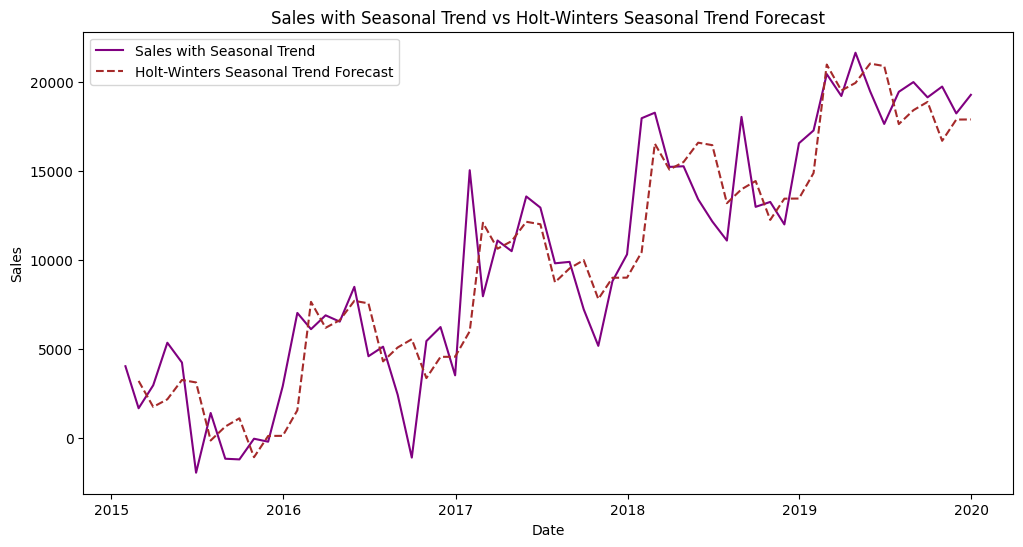

In [12]:
#plot sales seasonal trend and holt-winters seasonal trend forecast
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Seasonal_Trend'], label='Sales with Seasonal Trend', color='purple')
plt.plot(data.index, data['Holt_Winters_Seasonal_Trend_Forecast'], label="Holt-Winters Seasonal Trend Forecast", linestyle='--', color='brown')
plt.title("Sales with Seasonal Trend vs Holt-Winters Seasonal Trend Forecast")
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Holt-Winters-Three-Parameter Multiplicative ES

In [13]:
#Use the same data to apply holt-winters multiplicative seasonal method to forecast the new time series data with seasonal+trend
#Trend is additive and seasonal are multiplicative, seasonal period is 12 (monthly data)
holt_winters_mult_model = ExponentialSmoothing(data['Sales_Seasonal_Trend'], trend='add', seasonal='mul', seasonal_periods=12)
holt_winters_mult_fit = holt_winters_mult_model.fit()
data['Holt_Winters_Multiplicative_Seasonal_Trend_Forecast'] = holt_winters_mult_fit.fittedvalues.shift(1)

/Users/hendrikmeth/Python/PYTHON_TIME_SERIES_FORECASTING/.venv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


ValueError: endog must be strictly positive when usingmultiplicative trend or seasonal components.

uuuups - the multiplicative model only works with positive time-series values

So let's try with realistic (positive) Sales numbers

In [14]:
#Generate positive sample data for seasonal+trend time series forecasting
np.random.seed(0)
data['Sales_Seasonal_Trend'] = (5000 * (data.index.year - data.index.year.min()) +
                                  1000 * np.sin(2 * np.pi * data.index.month / 12) +
                                  np.random.normal(0, 500, len(data)))
data['Sales_Seasonal_Trend'] = data['Sales_Seasonal_Trend'].clip(lower=1)


In [15]:
data.describe()

,Sales_Actuals,Simple_Exponential_Smoothing_Forecast,Sales_Trend,Holt_Linear_Trend_Forecast,Sales_Seasonal_Trend,Holt_Winters_Seasonal_Trend_Forecast
count,60.000000,59.000000,60.000000,59.000000,60.000000,59.000000
mean,100383.300000,101940.631240,110536.634591,110808.666754,10098.360523,10047.376972
std,5343.871009,3036.615827,8509.514867,3209.928031,6934.154713,6430.887018
min,87235.000000,98073.158215,87129.020368,105068.494482,1.000000,-1082.429160
25%,97291.500000,99340.580031,105653.503556,108187.463403,4586.884091,4557.462061
50%,100470.500000,101213.225999,110688.973924,111030.527171,10108.508526,9989.059400
75%,103825.500000,104176.166947,115870.437230,113240.695179,15737.739669,15287.351127
max,111349.000000,108820.000000,128655.550790,118373.229945,21059.476653,21029.689635


In [16]:
#Use the same data to apply holt-winters multiplicative seasonal method to forecast the new time series data with seasonal+trend
#Trend is additive and seasonal are multiplicative, seasonal period is 12 (monthly data)
holt_winters_mult_model = ExponentialSmoothing(data['Sales_Seasonal_Trend'], trend='add', seasonal='mul', seasonal_periods=12)
holt_winters_mult_fit = holt_winters_mult_model.fit()
data['Holt_Winters_Multiplicative_Seasonal_Trend_Forecast'] = holt_winters_mult_fit.fittedvalues.shift(1)

/Users/hendrikmeth/Python/PYTHON_TIME_SERIES_FORECASTING/.venv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [17]:
#show available attribute names of the fitted multiplicative model
print("Available attributes of the fitted multiplicative model:")
print(holt_winters_mult_fit.__dict__.keys())

Available attributes of the fitted multiplicative model:
dict_keys(['_results', '__doc__'])


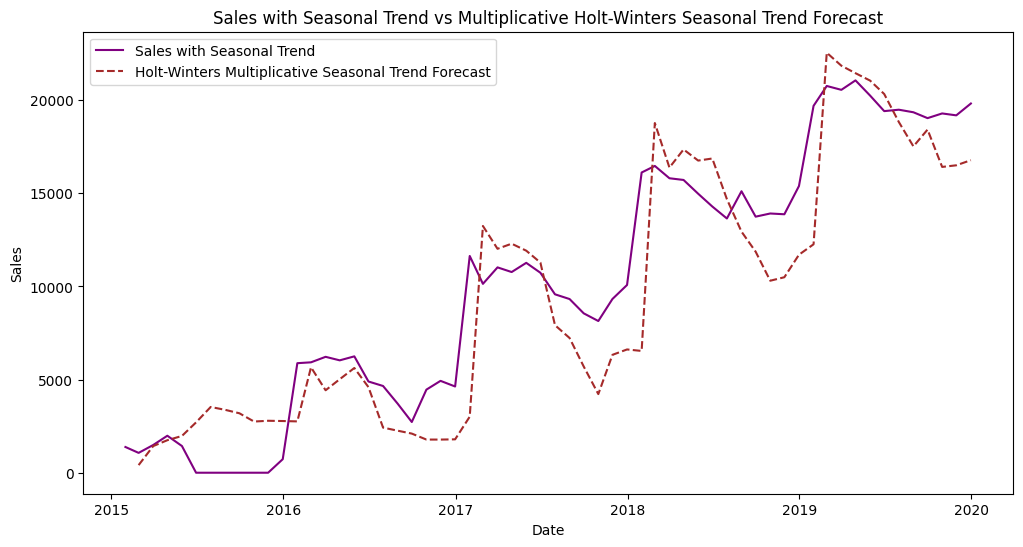

In [18]:
#plot multiplicative seasonal trend forecast vs sales seasonal trend
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Seasonal_Trend'], label='Sales with Seasonal Trend', color='purple')
plt.plot(data.index, data['Holt_Winters_Multiplicative_Seasonal_Trend_Forecast'], label="Holt-Winters Multiplicative Seasonal Trend Forecast", linestyle='--', color='brown')
plt.title("Sales with Seasonal Trend vs Multiplicative Holt-Winters Seasonal Trend Forecast")
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

In [19]:
#calculate the additive model for the same data
holt_winters_model = ExponentialSmoothing(data['Sales_Seasonal_Trend'], trend='add', seasonal='add', seasonal_periods=12)
holt_winters_fit = holt_winters_model.fit()
data['Additive_Holt_Winters_Seasonal_Trend_Forecast'] = holt_winters_fit.fittedvalues.shift(1)


/Users/hendrikmeth/Python/PYTHON_TIME_SERIES_FORECASTING/.venv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


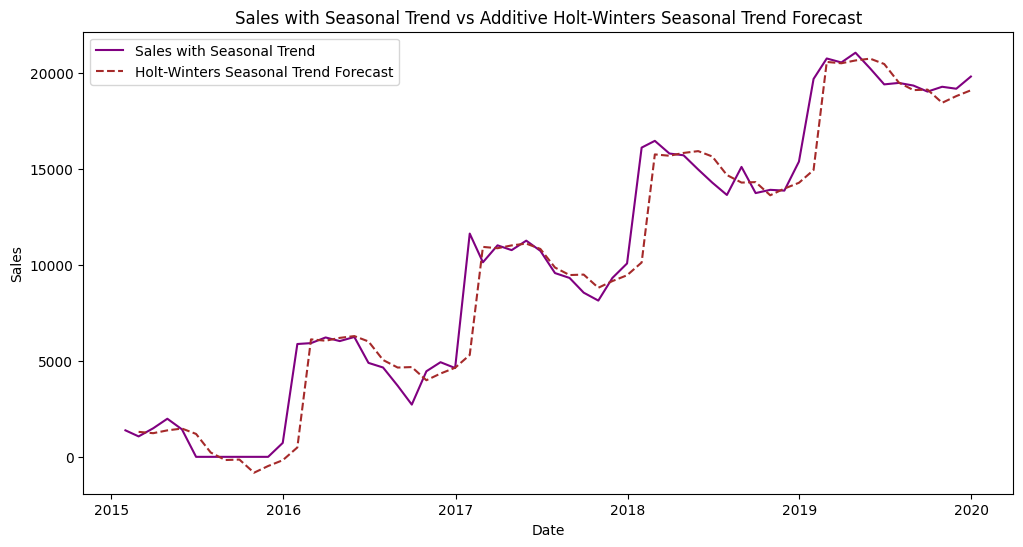

In [20]:
#plot the additive seasonal trend forecast vs sales seasonal trend
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Seasonal_Trend'], label='Sales with Seasonal Trend', color='purple')
plt.plot(data.index, data['Additive_Holt_Winters_Seasonal_Trend_Forecast'], label="Holt-Winters Seasonal Trend Forecast", linestyle='--', color='brown')
plt.title("Sales with Seasonal Trend vs Additive Holt-Winters Seasonal Trend Forecast")
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()